In [12]:
import pandas as pd
import numpy as np

# Set random seed for reproducibility
np.random.seed(42)

# Number of records
n_samples = 1000

# Generate dummy features (8 columns)
data = {
    'Applicant_ID': range(1001, 1001 + n_samples),
    'Age': np.random.randint(21, 65, size=n_samples),
    'Annual_Income_USD': np.random.randint(25000, 150000, size=n_samples),
    'Credit_Score': np.random.randint(300, 850, size=n_samples),
    'Loan_Amount_USD': np.random.randint(5000, 80000, size=n_samples),
    'Employment_Years': np.random.randint(0, 20, size=n_samples),
    'Prior_Default': np.random.choice([0, 1], size=n_samples, p=[0.85, 0.15]),
    'Loan_Approved': np.random.choice([0, 1], size=n_samples, p=[0.4, 0.6])
}

# Create DataFrame
df = pd.DataFrame(data)

# Adjust 'Loan_Approved' status based on simple rules to make it realistic
# e.g., low credit score or prior default makes rejection highly likely
df.loc[(df['Credit_Score'] < 550) | (df['Prior_Default'] == 1), 'Loan_Approved'] = 0
df.loc[(df['Credit_Score'] > 700) & (df['Annual_Income_USD'] > 60000), 'Loan_Approved'] = 1

# Display the shape and first 5 rows
print(f"Dataset Shape: {df.shape} (Columns: {list(df.columns)})")
display(df.head())

Dataset Shape: (1000, 8) (Columns: ['Applicant_ID', 'Age', 'Annual_Income_USD', 'Credit_Score', 'Loan_Amount_USD', 'Employment_Years', 'Prior_Default', 'Loan_Approved'])


,Applicant_ID,Age,Annual_Income_USD,Credit_Score,Loan_Amount_USD,Employment_Years,Prior_Default,Loan_Approved
0,1001,59,29018,391,37174,12,1,0
1,1002,49,36302,541,11581,13,0,0
2,1003,35,92506,301,76853,2,0,0
3,1004,63,66157,524,69046,9,0,0
4,1005,28,79917,415,54678,5,0,0


In [13]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import classification_report, confusion_matrix, accuracy_score

# Define features (X) and target (y)
# We drop 'Applicant_ID' as it's just an identifier, and 'Loan_Approved' as it is the label
features = ['Age', 'Annual_Income_USD', 'Credit_Score', 'Loan_Amount_USD', 'Employment_Years', 'Prior_Default']
X = df[features]
y = df['Loan_Approved']

# Split the dataset into training (80%) and testing (20%) sets
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Scale the features for better gradient descent performance in Logistic Regression
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Initialize and train the Logistic Regression model
model = LogisticRegression(random_state=42)
model.fit(X_train_scaled, y_train)

# Make predictions on the test set
y_pred = model.predict(X_test_scaled)

# Evaluate the model
accuracy = accuracy_score(y_test, y_pred)
print(f"Accuracy: {accuracy:.4f}\n")
print("Classification Report:")
print(classification_report(y_test, y_pred))

# Display feature coefficients to see what impacts approval the most
coefficients = pd.DataFrame({
    'Feature': features,
    'Coefficient': model.coef_[0]
}).sort_values(by='Coefficient', ascending=False)

print("Model Coefficients (Feature Importance):")
display(coefficients)

Accuracy: 0.8400

Classification Report:
              precision    recall  f1-score   support

           0       0.88      0.85      0.87       123
           1       0.78      0.82      0.80        77

    accuracy                           0.84       200
   macro avg       0.83      0.84      0.83       200
weighted avg       0.84      0.84      0.84       200

Model Coefficients (Feature Importance):


,Feature,Coefficient
2,Credit_Score,2.704266
1,Annual_Income_USD,0.487241
0,Age,0.020699
4,Employment_Years,-0.009983
3,Loan_Amount_USD,-0.134895
5,Prior_Default,-0.831754


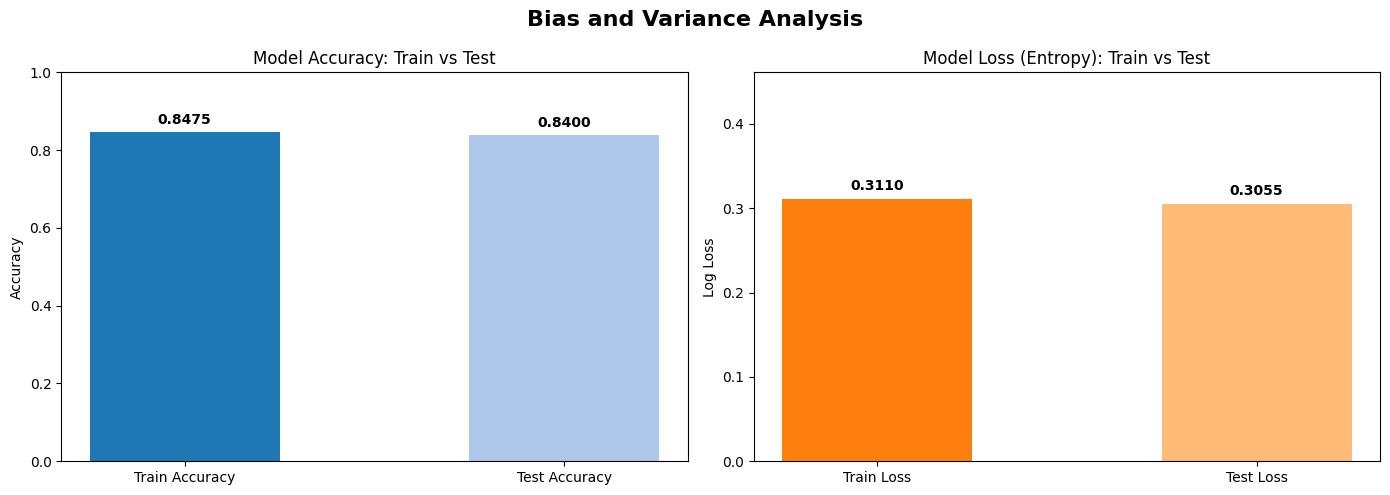

Training Accuracy: 0.8475 | Test Accuracy: 0.8400
Training Loss:     0.3110 | Test Loss:     0.3055

--- Bias & Variance Verdict ---
Low Bias & Low Variance (Well-balanced): The train accuracy (0.8475) and test accuracy (0.8400) are close and high, indicating the model generalizes well.


In [14]:
import matplotlib.pyplot as plt
from sklearn.metrics import log_loss

# Calculate predictions and probabilities for training and testing sets
y_train_pred = model.predict(X_train_scaled)
y_test_pred = model.predict(X_test_scaled)

y_train_prob = model.predict_proba(X_train_scaled)
y_test_prob = model.predict_proba(X_test_scaled)

# Calculate Accuracies
train_acc = accuracy_score(y_train, y_train_pred)
test_acc = accuracy_score(y_test, y_pred)

# Calculate Log Losses (good proxy for model error / variance)
train_loss = log_loss(y_train, y_train_prob)
test_loss = log_loss(y_test, y_test_prob)

# Create subplots to visualize Bias and Variance
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))

# 1. Accuracy Plot (Train vs Test)
metrics_acc = ['Train Accuracy', 'Test Accuracy']
values_acc = [train_acc, test_acc]
ax1.bar(metrics_acc, values_acc, color=['#1f77b4', '#aec7e8'], width=0.5)
ax1.set_ylim(0, 1.0)
ax1.set_ylabel('Accuracy')
ax1.set_title('Model Accuracy: Train vs Test')
for i, v in enumerate(values_acc):
    ax1.text(i, v + 0.02, f"{v:.4f}", ha='center', fontweight='bold')

# 2. Loss Plot (Train vs Test)
metrics_loss = ['Train Loss', 'Test Loss']
values_loss = [train_loss, test_loss]
ax2.bar(metrics_loss, values_loss, color=['#ff7f0e', '#ffbb78'], width=0.5)
ax2.set_ylim(0, max(values_loss) + 0.15)
ax2.set_ylabel('Log Loss')
ax2.set_title('Model Loss (Entropy): Train vs Test')
for i, v in enumerate(values_loss):
    ax2.text(i, v + 0.01, f"{v:.4f}", ha='center', fontweight='bold')

plt.suptitle('Bias and Variance Analysis', fontsize=16, fontweight='bold')
plt.tight_layout()
plt.show()

# Output text-based analysis
print(f"Training Accuracy: {train_acc:.4f} | Test Accuracy: {test_acc:.4f}")
print(f"Training Loss:     {train_loss:.4f} | Test Loss:     {test_loss:.4f}")

# Analysis commentary
bias_variance_gap = abs(train_acc - test_acc)
print("\n--- Bias & Variance Verdict ---")
if train_acc < 0.70:
    print("High Bias (Underfitting): The model performs poorly on both training and test data.")
elif bias_variance_gap > 0.05:
    print(f"High Variance (Overfitting): There is a significant gap ({bias_variance_gap:.4f}) between train and test performance.")
else:
    print(f"Low Bias & Low Variance (Well-balanced): The train accuracy ({train_acc:.4f}) and test accuracy ({test_acc:.4f}) are close and high, indicating the model generalizes well.")

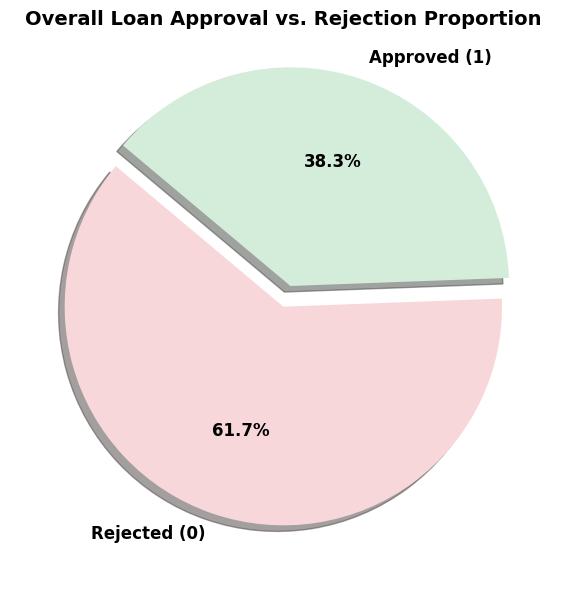

In [17]:
import matplotlib.pyplot as plt

# Count the number of approved and rejected loans
approval_counts = df['Loan_Approved'].value_counts()

# Map indices to human-readable labels
labels = ['Rejected (0)', 'Approved (1)']
sizes = [approval_counts.get(0, 0), approval_counts.get(1, 0)]
colors = ['#f8d7da', '#d4edda']
explode = (0, 0.1)  # highlight the Approved section

# Create the pie chart
fig, ax = plt.subplots(figsize=(8, 6))
ax.pie(
    sizes,
    explode=explode,
    labels=labels,
    autopct='%1.1f%%',
    startangle=140,
    colors=colors,
    shadow=True,
    textprops={'fontsize': 12, 'weight': 'bold'}
)

ax.set_title('Overall Loan Approval vs. Rejection Proportion', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

In [16]:
import ipywidgets as widgets
from IPython.display import display, HTML

# Create input widgets for each feature
age_widget = widgets.IntSlider(value=30, min=21, max=100, step=1, description='Age:')
income_widget = widgets.IntSlider(value=50000, min=10000, max=250000, step=5000, description='Income ($):')
credit_widget = widgets.IntSlider(value=650, min=300, max=850, step=10, description='Credit Score:')
loan_widget = widgets.IntSlider(value=20000, min=1000, max=150000, step=1000, description='Loan Amt ($):')
employment_widget = widgets.IntSlider(value=5, min=0, max=40, step=1, description='Work Years:')
default_widget = widgets.Dropdown(options=[('No', 0), ('Yes', 1)], value=0, description='Prior Default:')

# Prediction output area
output_area = widgets.Output()

def make_prediction(change):
    with output_area:
        output_area.clear_output()

        # Prepare input data
        custom_data = pd.DataFrame([{
            'Age': age_widget.value,
            'Annual_Income_USD': income_widget.value,
            'Credit_Score': credit_widget.value,
            'Loan_Amount_USD': loan_widget.value,
            'Employment_Years': employment_widget.value,
            'Prior_Default': default_widget.value
        }])

        # Scale data using the already fitted scaler
        custom_scaled = scaler.transform(custom_data)

        # Predict probability and class
        prediction = model.predict(custom_scaled)[0]
        probability = model.predict_proba(custom_scaled)[0][1]

        # Display results nicely
        if prediction == 1:
            display(HTML(f"<div style='padding: 10px; background-color: #d4edda; color: #155724; border-radius: 5px;'>"
                         f"<strong>Prediction: APPROVED</strong><br>"
                         f"Probability of approval: {probability*100:.2f}%</div>"))
        else:
            display(HTML(f"<div style='padding: 10px; background-color: #f8d7da; color: #721c24; border-radius: 5px;'>"
                         f"<strong>Prediction: REJECTED</strong><br>"
                         f"Probability of approval: {probability*100:.2f}%</div>"))

# Attach the event listener to all widgets
for widget in [age_widget, income_widget, credit_widget, loan_widget, employment_widget, default_widget]:
    widget.observe(make_prediction, names='value')

# Design Layout
input_box = widgets.VBox([
    widgets.HTML("<h4>Enter Applicant Details:</h4>"),
    age_widget,
    income_widget,
    credit_widget,
    loan_widget,
    employment_widget,
    default_widget
])

# Run prediction once initially to populate the output area
with output_area:
    make_prediction(None)

# Display UI
display(widgets.HBox([input_box, widgets.VBox([widgets.HTML("<h4>Model Prediction:</h4>"), output_area])], layout=widgets.Layout(gap='40px')))